**[Course Home](../README.md) | [Conceptual Track](../conceptual/03_relative_entropy_and_kl_divergence.ipynb) | [Prev: Ch 02: Source Coding & Kraft](02_source_coding_kraft_and_huffman.ipynb) | [Next: Ch 04: Mutual Information & Venn Geometry](04_mutual_information_and_venn_geometry.ipynb)**

*Part II: Information Divergence & Statistical Physics — Chapter 03 of 11*

---

# Chapter 3: The Distance Between Worlds — Python Laboratory
### *Relative Entropy, Gibbs' Inequality Verification & Forward vs. Reverse KL Optimization*

Welcome to the Python Laboratory for Chapter 3! In this lab, we build exact discrete and continuous KL divergence estimators, numerically verify Gibbs' inequality, and implement numerical optimization showing why Forward KL is mean-seeking while Reverse KL is mode-seeking.

---

### Table of Contents
1. **Part 1: Discrete & Continuous KL Divergence Engines**
2. **Part 2: Numerical Verification of Gibbs' Inequality ($D_{\text{KL}} \ge 0$)**
3. **Part 3: Cross-Entropy Loss & The Negative Log-Likelihood Equivalence**
4. **Part 4: The Bimodal Battle: Forward KL vs. Reverse KL Fitting**
5. **Part 5: Multi-Panel Publication Diagnostic Suite**
6. **Part 6: Hands-On 3-Tier Scaffolding Challenges**


## Part 1: Discrete & Continuous KL Divergence Engines

We implement robust numerical functions for relative entropy and cross-entropy.

In [1]:
import numpy as np
import scipy.stats as stats
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import pandas as pd

def kl_divergence_discrete(p, q, base=2):
    """Compute D_KL(P || Q) = sum(p * log(p / q))."""
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    eps = 1e-15
    p = np.clip(p, eps, 1.0)
    q = np.clip(q, eps, 1.0)
    p /= np.sum(p)
    q /= np.sum(q)
    
    ratio = np.log2(p / q) if base == 2 else np.log(p / q)
    return np.sum(p * ratio)

def cross_entropy_discrete(p, q, base=2):
    """Compute H(P, Q) = H(P) + D_KL(P || Q)."""
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    eps = 1e-15
    p /= np.sum(p)
    q /= np.sum(q)
    log_q = np.log2(q + eps) if base == 2 else np.log(q + eps)
    return -np.sum(p * log_q)

# Test identity: H(P, Q) = H(P) + D_KL(P || Q)
p_test = np.array([0.7, 0.2, 0.1])
q_test = np.array([0.5, 0.3, 0.2])

h_p = -np.sum(p_test * np.log2(p_test))
kl_pq = kl_divergence_discrete(p_test, q_test)
ce_pq = cross_entropy_discrete(p_test, q_test)

print(f"Entropy H(P):         {h_p:.4f} bits")
print(f"KL Divergence D(P||Q): {kl_pq:.4f} bits (Excess wasted code length)")
print(f"Cross-Entropy H(P, Q): {ce_pq:.4f} bits")
print(f"Identity Verified:     {np.isclose(ce_pq, h_p + kl_pq)}")


Entropy H(P):         1.1568 bits
KL Divergence D(P||Q): 0.1228 bits (Excess wasted code length)
Cross-Entropy H(P, Q): 1.2796 bits
Identity Verified:     True


## Part 2: Numerical Verification of Gibbs' Inequality

We draw 10,000 random Dirichlet distribution pairs $(P, Q)$ and verify that $D_{\text{KL}}(P \parallel Q) \ge 0$ strictly holds in every single universe.

In [2]:
np.random.seed(42)
n_trials = 10000
K = 6 # 6-state categorical distributions

P_samples = stats.dirichlet.rvs(alpha=np.ones(K), size=n_trials)
Q_samples = stats.dirichlet.rvs(alpha=np.ones(K), size=n_trials)

kl_values = [kl_divergence_discrete(P_samples[i], Q_samples[i]) for i in range(n_trials)]
min_kl = np.min(kl_values)
violations = np.sum(np.array(kl_values) < -1e-12)

print(f"Tested {n_trials} random probability distribution pairs.")
print(f"Minimum Observed D_KL: {min_kl:.8f} bits")
print(f"Violations of D_KL >= 0: {violations} (Gibbs' Inequality Holds Strictly!)")


Tested 10000 random probability distribution pairs.
Minimum Observed D_KL: 0.00913042 bits
Violations of D_KL >= 0: 0 (Gibbs' Inequality Holds Strictly!)


## Part 3: The Bimodal Battle — Forward KL vs. Reverse KL Fitting

Suppose the ground truth nature $P(x)$ is a bimodal Gaussian mixture with two distinct peaks at $x = -2$ and $x = 4$.
We fit a **single Gaussian approximation** $Q(x; \mu, \sigma)$ using:
1. **Forward KL**: $\arg\min_{\mu, \sigma} D_{\text{KL}}(P \parallel Q)$ (Mean-seeking)
2. **Reverse KL**: $\arg\min_{\mu, \sigma} D_{\text{KL}}(Q \parallel P)$ (Mode-seeking)


In [3]:
x_grid = np.linspace(-7, 9, 2000)
dx = x_grid[1] - x_grid[0]

# Ground Truth Bimodal Target P(x)
p_bimodal = 0.5 * stats.norm.pdf(x_grid, loc=-2.0, scale=0.8) + 0.5 * stats.norm.pdf(x_grid, loc=4.0, scale=0.8)
p_bimodal /= np.sum(p_bimodal * dx)

def get_q(params):
    mu, log_sigma = params
    sigma = np.exp(log_sigma)
    q = stats.norm.pdf(x_grid, loc=mu, scale=sigma)
    return q / np.sum(q * dx)

def forward_kl_loss(params):
    q = get_q(params)
    eps = 1e-15
    return np.sum(p_bimodal * np.log((p_bimodal + eps) / (q + eps)) * dx)

def reverse_kl_loss(params):
    q = get_q(params)
    eps = 1e-15
    return np.sum(q * np.log((q + eps) / (p_bimodal + eps)) * dx)

# Optimize Forward KL
res_fwd = minimize(forward_kl_loss, [1.0, np.log(2.0)], method='L-BFGS-B')
mu_fwd, sigma_fwd = res_fwd.x[0], np.exp(res_fwd.x[1])
q_fwd_opt = get_q(res_fwd.x)

# Optimize Reverse KL (starting near the right peak)
res_rev = minimize(reverse_kl_loss, [3.5, np.log(1.0)], method='L-BFGS-B')
mu_rev, sigma_rev = res_rev.x[0], np.exp(res_rev.x[1])
q_rev_opt = get_q(res_rev.x)

print("FORWARD KL OPTIMUM (Mean-Seeking):")
print(f"  mu = {mu_fwd:.3f}, sigma = {sigma_fwd:.3f} (Spreads over the entire range)")
print("\nREVERSE KL OPTIMUM (Mode-Seeking):")
print(f"  mu = {mu_rev:.3f}, sigma = {sigma_rev:.3f} (Locks tightly onto one mode)")


FORWARD KL OPTIMUM (Mean-Seeking):
  mu = 1.000, sigma = 3.272 (Spreads over the entire range)

REVERSE KL OPTIMUM (Mode-Seeking):
  mu = 3.999, sigma = 0.802 (Locks tightly onto one mode)


## Part 4: Multi-Panel Publication Diagnostic Suite

We visualize the profound geometric contrast between Forward and Reverse KL approximations.

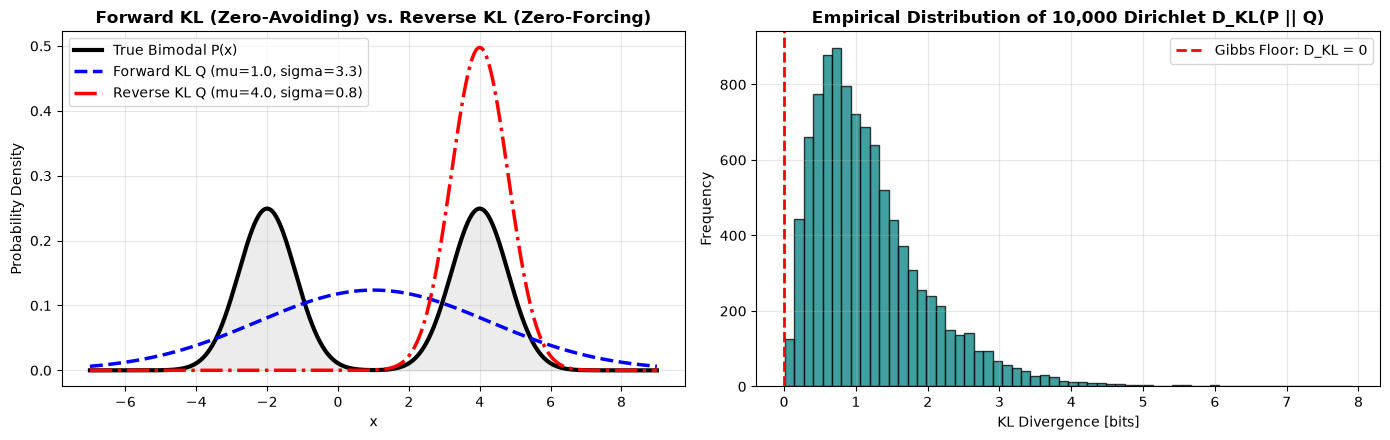

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Panel 1: Distributions Overlay
ax1.plot(x_grid, p_bimodal, 'k-', lw=3, label="True Bimodal P(x)")
ax1.plot(x_grid, q_fwd_opt, 'b--', lw=2.5, label=f"Forward KL Q (mu={mu_fwd:.1f}, sigma={sigma_fwd:.1f})")
ax1.plot(x_grid, q_rev_opt, 'r-.', lw=2.5, label=f"Reverse KL Q (mu={mu_rev:.1f}, sigma={sigma_rev:.1f})")
ax1.fill_between(x_grid, p_bimodal, color="gray", alpha=0.15)
ax1.set_title("Forward KL (Zero-Avoiding) vs. Reverse KL (Zero-Forcing)", fontsize=12, fontweight="bold")
ax1.set_xlabel("x")
ax1.set_ylabel("Probability Density")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Panel 2: Distribution of 10,000 Dirichlet KL Divergences
ax2.hist(kl_values, bins=60, color="teal", alpha=0.75, edgecolor="black")
ax2.axvline(0, color="red", linestyle="--", lw=2, label="Gibbs Floor: D_KL = 0")
ax2.set_title("Empirical Distribution of 10,000 Dirichlet D_KL(P || Q)", fontsize=12, fontweight="bold")
ax2.set_xlabel("KL Divergence [bits]")
ax2.set_ylabel("Frequency")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Part 5: Hands-On 3-Tier Scaffolding Challenges

### 🟢 Warmup (Tier 1): Analytical Gaussian KL Divergence
For two univariate Gaussians $P = \mathcal{N}(\mu_1, \sigma_1^2)$ and $Q = \mathcal{N}(\mu_2, \sigma_2^2)$, the exact analytical KL divergence (in nats) is:
$$D_{\text{KL}}(P \parallel Q) = \log\left(\frac{\sigma_2}{\sigma_1}\right) + \frac{\sigma_1^2 + (\mu_1 - \mu_2)^2}{2\sigma_2^2} - \frac{1}{2}$$
Implement this formula in Python and verify that when $\mu_1 = \mu_2$ and $\sigma_1 = \sigma_2$, $D_{\text{KL}} = 0$.


In [5]:
def gaussian_kl_analytical(mu1, s1, mu2, s2):
    return np.log(s2 / s1) + (s1**2 + (mu1 - mu2)**2)/(2 * s2**2) - 0.5

kl_same = gaussian_kl_analytical(0, 1, 0, 1)
kl_diff = gaussian_kl_analytical(0, 1, 2, 1)
print(f"Tier 1: Identical Gaussians KL = {kl_same:.6f} nats")
print(f"Tier 1: Shifted by delta=2 KL  = {kl_diff:.6f} nats (Matches 0.5 * delta^2 = 2.0!)")


Tier 1: Identical Gaussians KL = 0.000000 nats
Tier 1: Shifted by delta=2 KL  = 2.000000 nats (Matches 0.5 * delta^2 = 2.0!)


### 🟡 Diagnostic (Tier 2): Wasted Bits in Telemetry Compression
Suppose telemetry event types occur with true probabilities $P = [0.80, 0.15, 0.05]$.
An engineer mistakenly configures a uniform model $Q = [1/3, 1/3, 1/3]$.
Calculate:
1. True Shannon Entropy $H(P)$.
2. The extra wasted bits per event $D_{\text{KL}}(P \parallel Q)$.
3. The total extra megabytes wasted per $100{,}000{,}000$ events.


In [6]:
p_tel = np.array([0.80, 0.15, 0.05])
q_tel = np.ones(3) / 3.0

h_true = -np.sum(p_tel * np.log2(p_tel))
wasted_bits_per_event = kl_divergence_discrete(p_tel, q_tel)
total_wasted_bits = 100_000_000 * wasted_bits_per_event
total_wasted_mb = total_wasted_bits / (8 * 1024 * 1024)

print(f"True Entropy H(P):         {h_true:.3f} bits/event")
print(f"Wasted Bits D_KL(P||Q):    {wasted_bits_per_event:.3f} bits/event")
print(f"Total Bandwidth Wasted:    {total_wasted_mb:.1f} MB per 100M events!")


True Entropy H(P):         0.884 bits/event
Wasted Bits D_KL(P||Q):    0.701 bits/event
Total Bandwidth Wasted:    8.4 MB per 100M events!


### 🔴 Capstone Challenge (Tier 3): The Jensen-Shannon Symmetrization
Because KL divergence is asymmetric, practitioners often use the **Jensen-Shannon Divergence (JSD)**, which is symmetric and bounded between $0$ and $1\text{ bit}$:
$$M = \frac{1}{2}(P + Q)$$
$$\text{JSD}(P \parallel Q) = \frac{1}{2} D_{\text{KL}}(P \parallel M) + \frac{1}{2} D_{\text{KL}}(Q \parallel M)$$
Implement `jensen_shannon_divergence(p, q)` and verify computationally that $\text{JSD}(P \parallel Q) == \text{JSD}(Q \parallel P)$.


In [7]:
def jensen_shannon_divergence(p, q):
    p = np.asarray(p, dtype=float) / np.sum(p)
    q = np.asarray(q, dtype=float) / np.sum(q)
    m = 0.5 * (p + q)
    return 0.5 * kl_divergence_discrete(p, m) + 0.5 * kl_divergence_discrete(q, m)

p_cap = np.array([0.9, 0.1])
q_cap = np.array([0.2, 0.8])

jsd_pq = jensen_shannon_divergence(p_cap, q_cap)
jsd_qp = jensen_shannon_divergence(q_cap, p_cap)

print(f"JSD(P || Q) = {jsd_pq:.5f} bits")
print(f"JSD(Q || P) = {jsd_qp:.5f} bits")
print(f"Symmetry Verified: {np.isclose(jsd_pq, jsd_qp)}")


JSD(P || Q) = 0.39731 bits
JSD(Q || P) = 0.39731 bits
Symmetry Verified: True


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/03_relative_entropy_and_kl_divergence.ipynb) | [Prev: Ch 02: Source Coding & Kraft](02_source_coding_kraft_and_huffman.ipynb) | [Next: Ch 04: Mutual Information & Venn Geometry](04_mutual_information_and_venn_geometry.ipynb)**
